# Ingeniería de características
### Objetivo y alcance
La ingeniería de caracteristicas es una etapa crucial en el preprocesado.  Es util para limpiar y obtener caracterísitcas de entrada útiles en los modelos a desarrollar.


## Construcción
### Preparación del conjunto

Parte de la ingeniería de características conlleva a aprovechar el conocimiento que se tiene sobr ela aplicación y es que los objetos a detectar son proporcionales o asociados a una persona.  
Una primer aproximación lleva a generar datos de las cabezas para calcular dimensiones relativas de los objetos:

In [9]:
from pathlib import Path

import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


IMAGE_DIR = Path("../DataCapture/raw")
EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

# Ajustables: un píxel se considera "negro" si sus canales B, G y R
# están dentro de este rango.
BLACK_MAX = 40

# Filtros iniciales para descartar ruido y regiones improbables.
MIN_WIDTH_PX = 20
MIN_HEIGHT_PX = 20
MIN_AREA_REL = 0.001
MAX_AREA_REL = 0.20
MIN_RECTANGULARITY = 0.60
MIN_ASPECT_RATIO = 0.35
MAX_ASPECT_RATIO = 2.00

rows = []

for image_path in sorted(IMAGE_DIR.iterdir()):
    if image_path.suffix.lower() not in EXTENSIONS:
        continue

    image = cv2.imread(str(image_path))
    if image is None:
        print(f"No se pudo leer: {image_path.name}")
        continue

    image_height, image_width = image.shape[:2]
    image_area = image_width * image_height

    # Máscara blanca para píxeles cercanos al negro.
    black_mask = cv2.inRange(
        image,
        (0, 0, 0),
        (BLACK_MAX, BLACK_MAX, BLACK_MAX)
    )

    # Cada región negra conectada devuelve x, y, ancho, alto y área.
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
        black_mask,
        connectivity=8
    )

    # La etiqueta 0 es el fondo de la máscara; se omite.
    for label in range(1, num_labels):
        x, y, w, h, pixel_area = stats[label]

        area_rel = pixel_area / image_area
        aspect_ratio = w / h if h else 0
        rectangularity = pixel_area / (w * h) if w * h else 0

        if w < MIN_WIDTH_PX or h < MIN_HEIGHT_PX:
            continue
        if not MIN_AREA_REL <= area_rel <= MAX_AREA_REL:
            continue
        if not MIN_ASPECT_RATIO <= aspect_ratio <= MAX_ASPECT_RATIO:
            continue
        if rectangularity < MIN_RECTANGULARITY:
            continue

        rows.append({
            "imagen": image_path.name,
            "head_id": sum(r["imagen"] == image_path.name for r in rows) + 1,
            "x": int(x),
            "y": int(y),
            "w": int(w),
            "h": int(h),
            "image_width": int(image_width),
            "image_height": int(image_height),
            "centro_x": float(centroids[label][0]),
            "centro_y": float(centroids[label][1]),
            "area_relativa": area_rel,
            "aspect_ratio": aspect_ratio,
            "rectangularidad": rectangularity,
        })

head_df = pd.DataFrame(rows)

head_df.head()
head_df.to_csv("../DataCapture/mediciones_mascara_rostro.csv", index=False)


### Creación de variables nuevas y generación de características

In [10]:
IMAGE_DIR = Path("../DataCapture/raw")
CSV_PATH = Path("../DataCapture/anotaciones.csv")

annotations = pd.read_csv(CSV_PATH)
heads = pd.read_csv("../DataCapture/mediciones_mascara_rostro.csv")
heads = heads.groupby("imagen").agg({"x": "mean", "y": "mean", "w": "mean", "h": "mean"}).reset_index()

required = {"imagen", "x", "y", "w", "h"}
missing = required - set(annotations.columns)
if missing:
    raise ValueError(f"Faltan columnas en el CSV: {sorted(missing)}")

records = []

for row in annotations.itertuples(index=False):
    image_path = IMAGE_DIR / Path(row.imagen).name
    image = cv2.imread(str(image_path))
    head_data = heads[heads["imagen"] == row.imagen]

    if image is None:
        print(f"No se pudo leer: {image_path.name}")
        continue

    image_height, image_width = image.shape[:2]
    head_height=np.mean(head_data["h"])
    head_width=np.mean(head_data["w"])
    x, y, w, h = map(float, (row.x, row.y, row.w, row.h))

    if w <= 0 or h <= 0:
        print(f"Caja inválida en {image_path.name}")
        continue

    records.append({
        "imagen": image_path.name,  # identificador; no predictor
        "x": x,
        "y": y,
        "w": w,
        "h": h,
        "image_width": image_width,
        "image_height": image_height,
        "center_x_norm": (x + w / 2) / image_width,
        "center_y_norm": (y + h / 2) / image_height,
        "box_width_rel": w / image_width,
        "box_width_rel_head": w / head_width,
        "box_height_rel": h / image_height,
        "box_height_rel_head": h / head_height,
        "box_area_rel": (w * h) / (image_width * image_height),
        "box_area_rel_head": (w * h) / (head_width * head_height),
        "box_aspect_ratio": w / h,
    })

features_df = pd.DataFrame(records)
features_df.head()
anotations_baseline = features_df[["imagen", "x", "y", "w", "h", "image_width", "image_height"]].copy()
anotations_baseline.to_csv("../DataCapture/anotaciones_baseline.csv", index=False)


No se pudo leer: captura_20261019_105156_401150.jpg


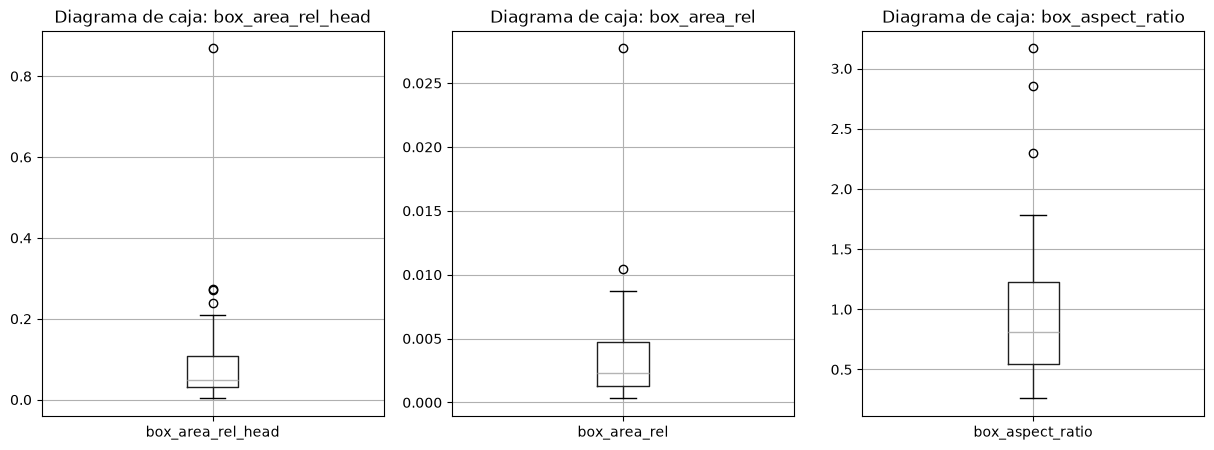

In [11]:
i=0
plt.figure(figsize=(15,5))
for col in ["box_area_rel_head","box_area_rel","box_aspect_ratio"]:
    i+=1
    #plt.figure(figsize=(5,5))
    plt.subplot(1, 3, i)
    features_df.boxplot(column=col)
    plt.title(f"Diagrama de caja: {col}")

Se observa que los objetos a encontrar respecto al tamaño de la cabena caen en escalas pequeñas y con sesgo hacia arriba, de igual manera el amontonamiento ocurre en escalas bajas.  En cuanto a la forma se observa una aproximación casi cuadrada abarcando varias geometrías.

## Normalización

### Distribuciones y binning
Dado el sesgo a la derecha observado en variables como (box_area_rel), se aplica transformación logarítmica (log1p) para normalizar la distribución en aquellas cuyo skewness esté fuera del rango -1 a 1.

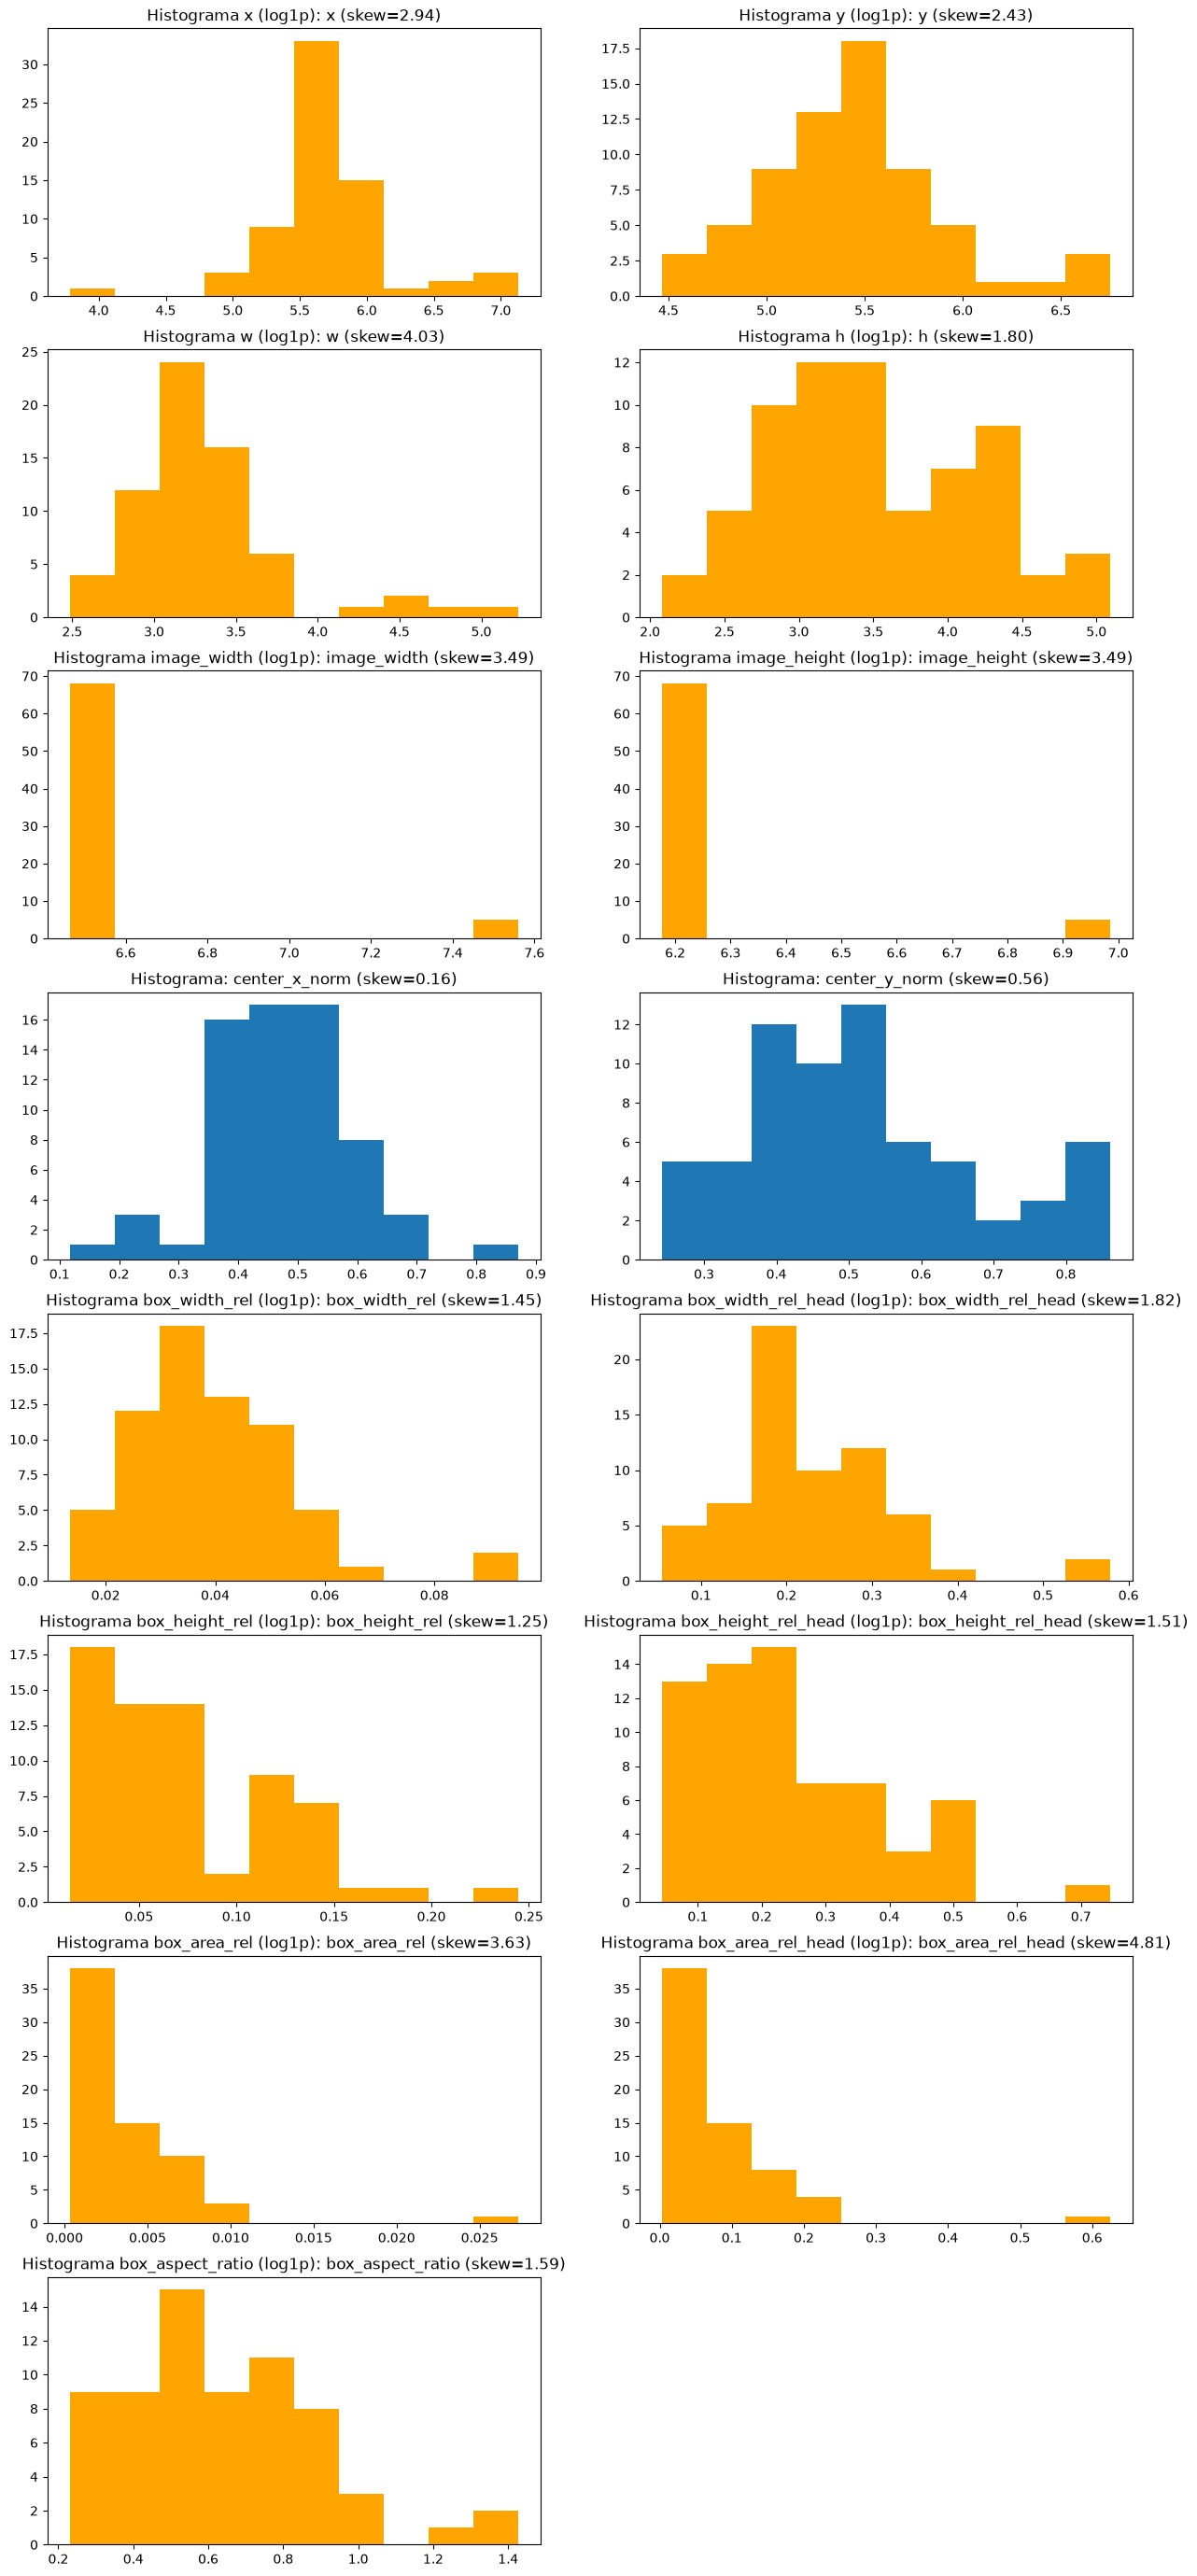

In [12]:
# Usar transformaciones (log1p) a aquellas con sesgo
# Se obtienen distribuciones o efectos a mejorar las caracteristicas de entrada.
features_df_norm=features_df.copy()
cols = features_df_norm.select_dtypes(include=[np.number]).columns
num_cols = len(cols)
n_rows = np.ceil(num_cols/2).astype(int)
plt.figure(figsize=(15,35))
i=0
for col in cols:
    i+=1
    skewness = features_df_norm[col].skew()
    if skewness > 1 or skewness < -1:
        features_df_norm[f"{col}_log1p"] = np.log1p(features_df_norm[col])
        plt.subplot(n_rows,2, i)
        plt.hist(features_df_norm[f"{col}_log1p"],color='orange')
        plt.title(f"Histograma {col} (log1p): {col} (skew={skewness:.2f})")
        features_df_norm.drop(columns=[col], inplace=True)
        #features_df_norm.columns = features_df_norm.columns.str.replace(col, f"{col}_log1p")
    else:
        plt.subplot(n_rows,2, i)
        plt.hist(features_df_norm[col])
        plt.title(f"Histograma: {col} (skew={skewness:.2f})")

###  Normalización / escalamiento unitario

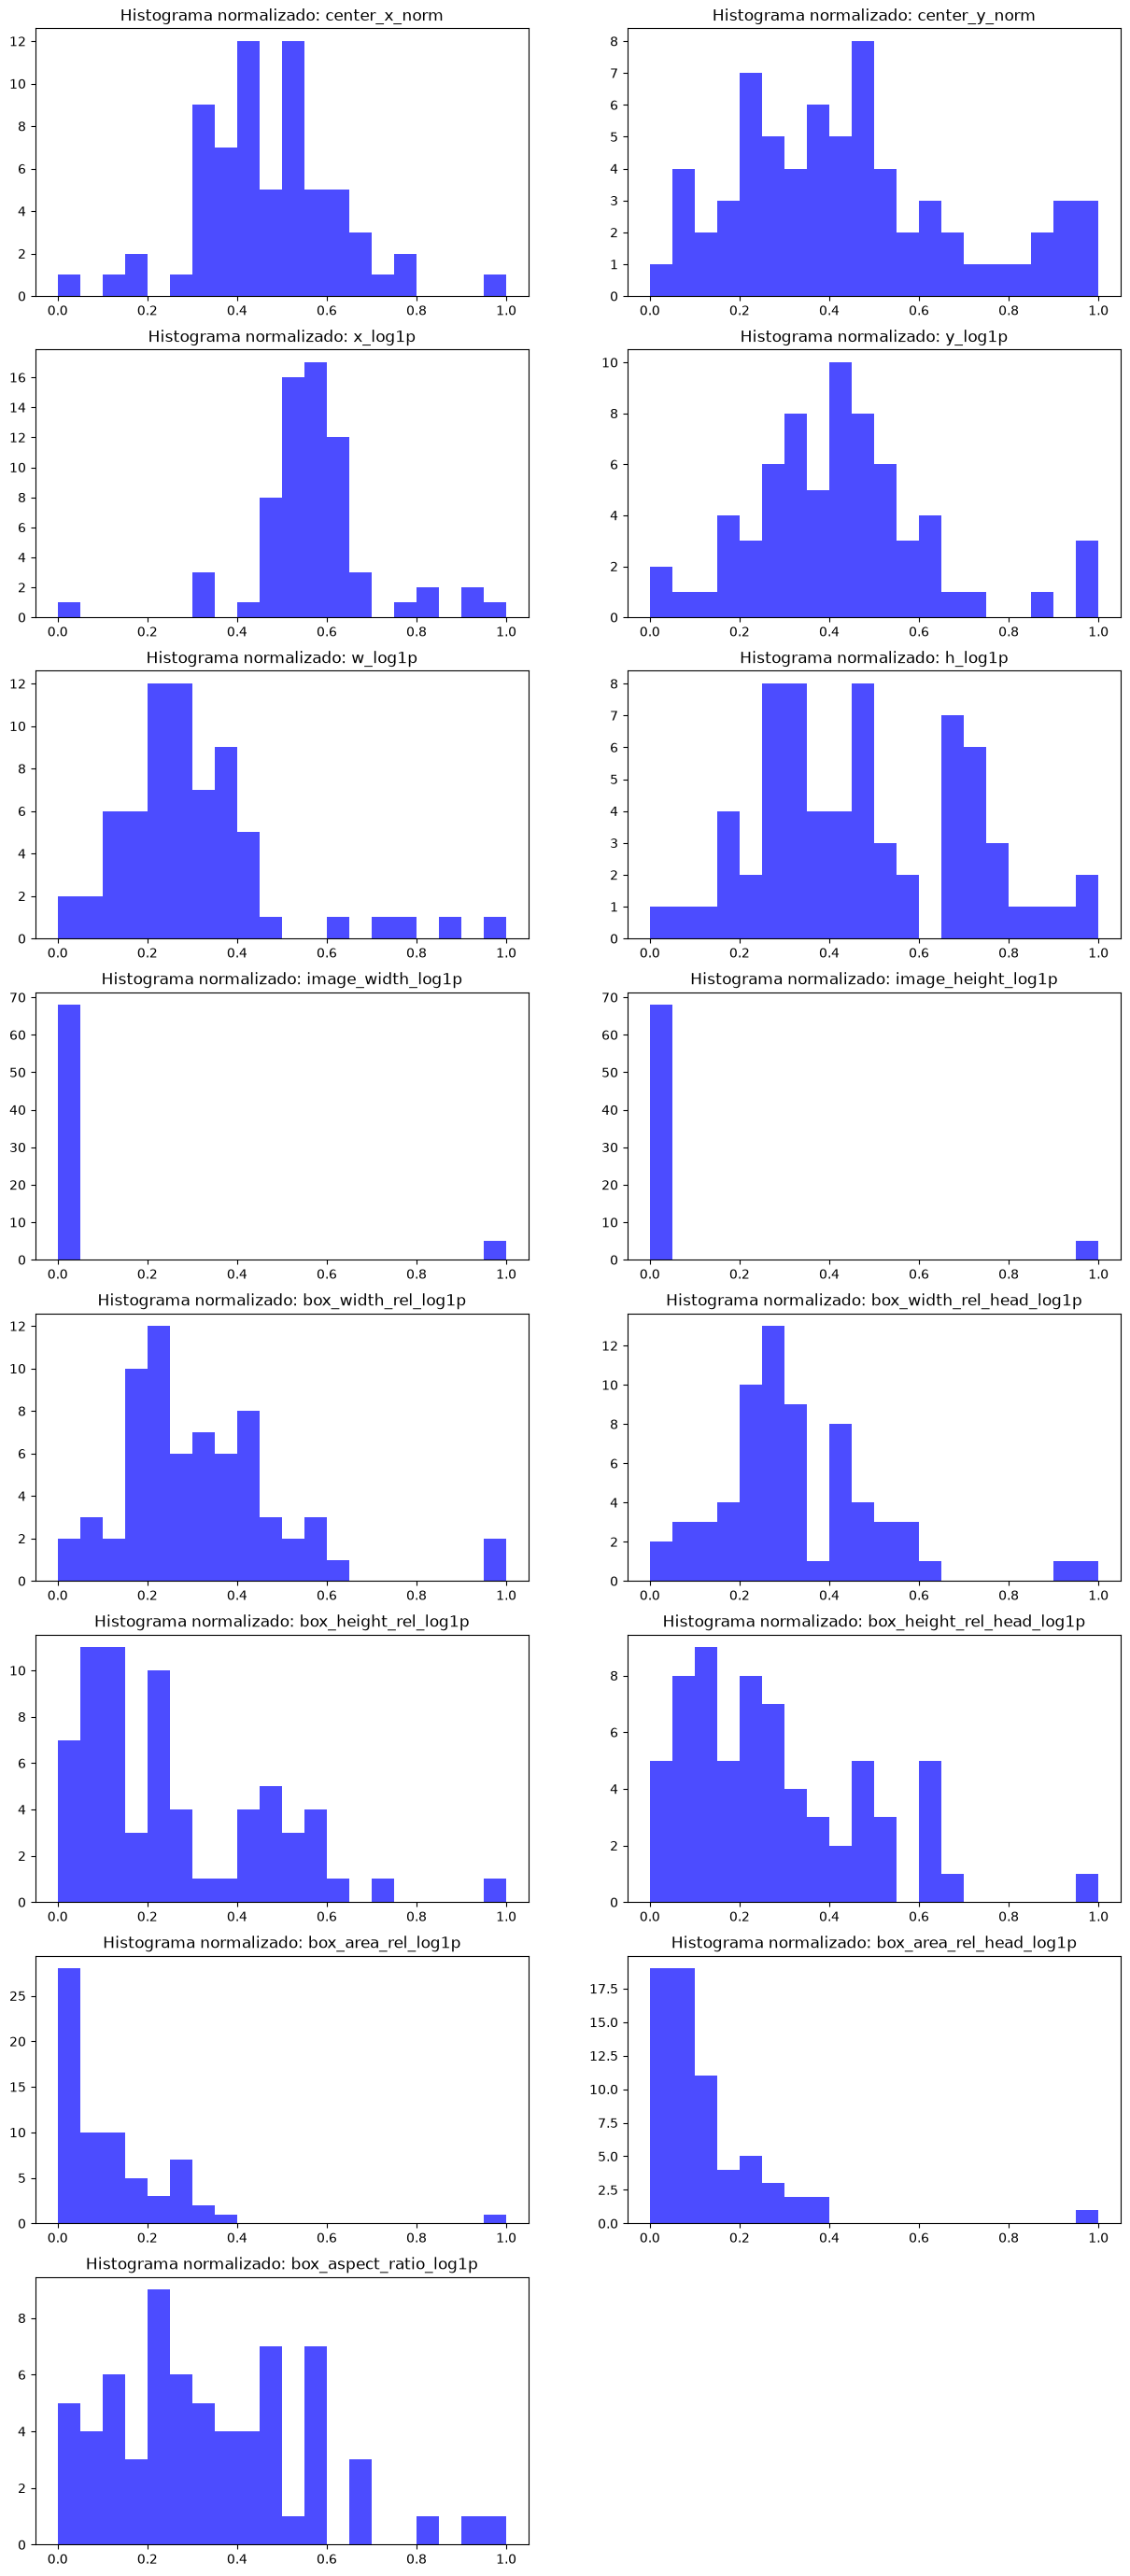

In [13]:

numeric_cols = features_df_norm.select_dtypes(include=[np.number]).columns
for col in numeric_cols:
    min_val = features_df_norm[col].min()
    max_val = features_df_norm[col].max()
    if max_val - min_val > 0:
        features_df_norm[col] = (features_df_norm[col] - min_val) / (max_val - min_val)
    else:
        features_df_norm[col] = 0.0  # Si todos los valores son iguales, asignar 0.0

cols = features_df_norm.select_dtypes(include=[np.number]).columns
num_cols = len(cols)
n_rows = np.ceil(num_cols/2).astype(int)
plt.figure(figsize=(15,35))
i=0
for i, col in enumerate(numeric_cols):
    plt.subplot(n_rows,2, i + 1)
    plt.hist(features_df_norm[col], bins=20, color='blue', alpha=0.7)
    plt.title(f"Histograma normalizado: {col}")

## Selección/extracción
### Codificación y escalamiento
La primer etapa es descartar dentro de las variables normalizadas aquellas que no presentan variación.

array([[<Axes: title={'center': 'center_x_norm'}>,
        <Axes: title={'center': 'center_y_norm'}>,
        <Axes: title={'center': 'x_log1p'}>,
        <Axes: title={'center': 'y_log1p'}>],
       [<Axes: title={'center': 'w_log1p'}>,
        <Axes: title={'center': 'h_log1p'}>,
        <Axes: title={'center': 'image_width_log1p'}>,
        <Axes: title={'center': 'image_height_log1p'}>],
       [<Axes: title={'center': 'box_width_rel_log1p'}>,
        <Axes: title={'center': 'box_width_rel_head_log1p'}>,
        <Axes: title={'center': 'box_height_rel_log1p'}>,
        <Axes: title={'center': 'box_height_rel_head_log1p'}>],
       [<Axes: title={'center': 'box_area_rel_log1p'}>,
        <Axes: title={'center': 'box_area_rel_head_log1p'}>,
        <Axes: title={'center': 'box_aspect_ratio_log1p'}>, <Axes: >]],
      dtype=object)

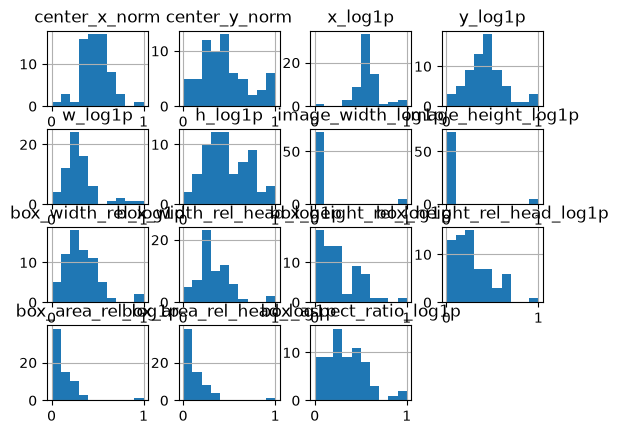

In [14]:
for col in numeric_cols:
    if features_df_norm[col].nunique() <= 1:
        features_df_norm.drop(columns=[col], inplace=True)

features_df_norm.hist()


### Seleccion de características
Aplicando PCA

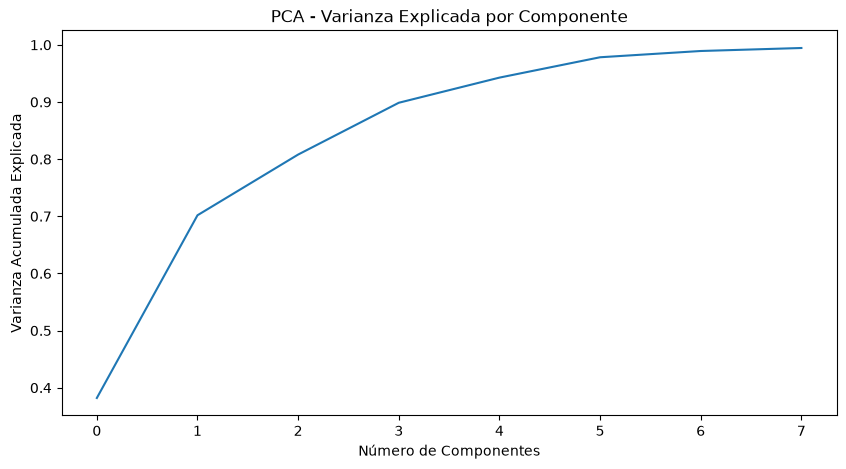

In [15]:
#Se aplica PCA para reducir la dimensionalidad y seleccionar las características más importantes.
from sklearn.decomposition import PCA
pca = PCA(n_components=0.99)  # Mantener el 95% de la varianza
numeric_cols = features_df_norm.select_dtypes(include=[np.number]).columns
features_df_pca = pca.fit_transform(features_df_norm[numeric_cols].dropna())
plt.figure(figsize=(10, 5))
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel('Número de Componentes')
plt.ylabel('Varianza Acumulada Explicada')
plt.title('PCA - Varianza Explicada por Componente')
plt.show()

En general parece que 4 variables bastan para explicar la mayoría de las condiciones geométricas de los objetos almacenados en la base de datos de objetos con potencial de generar daño a la pintura.

## Convoluciones
Puesto que las imagenes a utilizar serán procesadas por una red neural convolucional, es preciso mencionar que la extracción de características provendría tambien desde la sintonizacion de la red misma

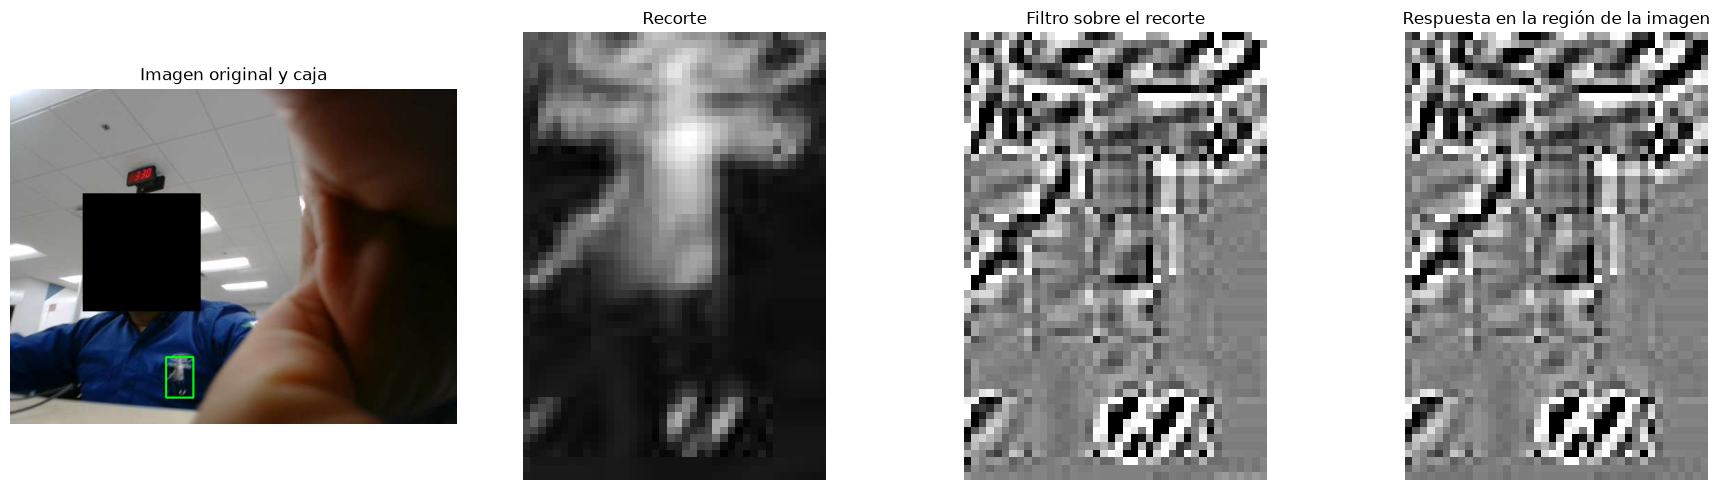

In [16]:
# Cambia estas rutas y coordenadas por un ejemplo real.
imagen_prueba="captura_20261003_153016_534962.jpg"
crop_prueba=imagen_prueba.replace('.jpg', '_001.jpg')
SOURCE_PATH =Path("../DataCapture/raw/captura_20261003_153016_534962.jpg")
CROP_PATH = Path("../DataCapture/NG/captura_20261003_153016_534962_001.jpg")

# Coordenadas de ESA caja en la imagen original, tomadas del CSV.
x, y, w, h = features_df[features_df["imagen"]==imagen_prueba][["x","y","w","h"]].iloc[0]

source = cv2.imread(SOURCE_PATH)
crop = cv2.imread(str(CROP_PATH))

if source is None:
    raise FileNotFoundError(f"No se pudo leer la imagen original: {SOURCE_PATH.name}")
if crop is None:
    raise FileNotFoundError(f"No se pudo leer el recorte: {CROP_PATH.name}")

# Validar y limitar la caja a los bordes de la imagen.
image_h, image_w = source.shape[:2]
x1 = max(0, int(x))
y1 = max(0, int(y))
x2 = min(image_w, int(x + w))
y2 = min(image_h, int(y + h))

if x2 <= x1 or y2 <= y1:
    raise ValueError("La caja no cae dentro de los límites de la imagen.")

# El recorte de referencia se obtiene de la imagen original usando la caja.
source_crop = source[y1:y2, x1:x2]

# A escala de grises, para que ambos filtros trabajen sobre el mismo canal.
source_gray = cv2.cvtColor(source, cv2.COLOR_BGR2GRAY)
crop_gray = cv2.cvtColor(source_crop, cv2.COLOR_BGR2GRAY)

# Kernel fijo: resalta cambios de intensidad locales.
kernel = np.array([
    [0,  1, 0],
    [1, -4, 1],
    [0,  1, 0],
], dtype=np.float32)

# La misma operación y kernel para el recorte y la imagen completa.
response_crop = cv2.filter2D(
    crop_gray, cv2.CV_32F, kernel, borderType=cv2.BORDER_REFLECT101
)
response_full = cv2.filter2D(
    source_gray, cv2.CV_32F, kernel, borderType=cv2.BORDER_REFLECT101
)

# Extraer de la respuesta completa la región que corresponde a la caja.
response_full_roi = response_full[y1:y2, x1:x2]

# Usar el mismo rango de visualización para comparar respuestas.
limit = np.percentile(
    np.abs(np.concatenate([
        response_crop.ravel(),
        response_full.ravel()
    ])),
    99
)
limit = max(float(limit), 1e-6)

# Dibujar la caja en una copia de la imagen original.
source_display = source.copy()
cv2.rectangle(source_display, (x1, y1), (x2 - 1, y2 - 1), (0, 255, 0), 2)
source_display = cv2.cvtColor(source_display, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(source_display)
axes[0].set_title("Imagen original y caja")
axes[1].imshow(crop_gray, cmap="gray")
axes[1].set_title("Recorte")
axes[2].imshow(response_crop, cmap="gray", vmin=-limit, vmax=limit)
axes[2].set_title("Filtro sobre el recorte")
axes[3].imshow(response_full_roi, cmap="gray", vmin=-limit, vmax=limit)
axes[3].set_title("Respuesta en la región de la imagen")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


## Conclusiones
Haciendo uso de las imágenes presentes se pudo hacer un estudio de las características geométricas de los recortes que incumplen el estandar de vestimenta.  
Se hizo uso del conocimiento a priori para seleccionar regularizaciones de tales valores: _al tener los accesorios asociados a una persona, se hizo uso del recorte de la cabeza para justamente tener una noción geométrica del objeto relativo a su portador_  
El presente sistema presenta limitaciones ya que se ha enfocado únicamente en los recortes dentro de una imagen y su escalabilidad dependerá en gran medida de qué tan estandarizada se encuentre la captura.  Para efectos prácticos el ejercicio permitió llegar a una selección de variables útiles.

<!-- ## Conclusiones
Haciendo uso de las imágenes presentes se pudo hacer un estudio de las características geométricas de los recortes que incumplen el estandar de vestimenta.  
Se hizo uso del conocimiento a priori para seleccionar regularizaciones de tales valores: _al tener los accesorios asociados a una persona, se hizo uso del recorte de la cabeza para justamente tener una noción geométrica del objeto relativo a su portador_  
El presente sistema presenta limitaciones ya que se ha enfocado únicamente en los recortes dentro de una imagen y su escalabilidad dependerá en gran medida de qué tan estandarizada se encuentre la captura.  Para efectos prácticos el ejercicio permitió llegar a una selección de variables útiles. -->